In [27]:
%matplotlib inline

# Solution 3 — Radiation equilibrium and lattice comparison

Load the rings saved in notebooks 1 and 2 and compare their radiation equilibrium side by side.

Complete the missing code to compare the two rings and compute their damping times. Use the supplied examples as a guide.

### Imports

In [28]:
import matplotlib.pyplot as plt
import xtrack as xt

### Load the rings

In [29]:
ring_fodo = xt.load('ring_fodo.json')
ring_dba = xt.load('ring_dba.json')

Loading line from dict:   0%|          | 0/105 [00:00<?, ?it/s]

Done loading line from dict.           


Loading line from dict:   0%|          | 0/208 [00:00<?, ?it/s]

Done loading line from dict.           


### Radiation integrals

See the [radiation-integral outputs in the Xsuite reference](https://xsuite.readthedocs.io/en/latest/apireference.html).

See [Section 9.3 — "Radiation integrals" in the Xsuite physics manual](https://xsuite.github.io/xsuite/docs/physics_manual/physics_man.pdf#page=142) for the relations between radiation integrals, equilibrium emittances, energy loss, and damping rates. Damping times are the reciprocals of the amplitude damping rates.

In [30]:
# Use sliced copies to sample the optics inside the magnets.
slicing_strategies = [
    xt.Strategy(slicing=None),
    xt.Strategy(slicing=xt.Uniform(100, mode='thick'), element_type=xt.Bend),
    xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
]

ring_fodo_rad = ring_fodo.copy(shallow=True)
ring_fodo_rad.slice_thick_elements(slicing_strategies=slicing_strategies)

ring_dba_rad = ring_dba.copy(shallow=True)
ring_dba_rad.slice_thick_elements(slicing_strategies=slicing_strategies)

Slicing line:   0%|          | 0/192 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/384 [00:00<?, ?it/s]

{'mid_straight.0': ['mid_straight.0'],
 '||drift_1::0': ['||drift_1'],
 'qf1.0': ['qf1.0_entry',
  'qf1.0..entry_map',
  'qf1.0..0',
  'qf1.0..1',
  'qf1.0..exit_map',
  'qf1.0_exit'],
 '||drift_2::0': ['||drift_2'],
 'qd1.0': ['qd1.0_entry',
  'qd1.0..entry_map',
  'qd1.0..0',
  'qd1.0..1',
  'qd1.0..exit_map',
  'qd1.0_exit'],
 '||drift_3::0': ['||drift_3'],
 'bend.0': ['bend.0_entry',
  'bend.0..entry_map',
  'bend.0..0',
  'bend.0..1',
  'bend.0..2',
  'bend.0..3',
  'bend.0..4',
  'bend.0..5',
  'bend.0..6',
  'bend.0..7',
  'bend.0..8',
  'bend.0..9',
  'bend.0..10',
  'bend.0..11',
  'bend.0..12',
  'bend.0..13',
  'bend.0..14',
  'bend.0..15',
  'bend.0..16',
  'bend.0..17',
  'bend.0..18',
  'bend.0..19',
  'bend.0..20',
  'bend.0..21',
  'bend.0..22',
  'bend.0..23',
  'bend.0..24',
  'bend.0..25',
  'bend.0..26',
  'bend.0..27',
  'bend.0..28',
  'bend.0..29',
  'bend.0..30',
  'bend.0..31',
  'bend.0..32',
  'bend.0..33',
  'bend.0..34',
  'bend.0..35',
  'bend.0..36',
  'b

In [31]:
# Compute both Twiss tables with radiation integrals.
tw_fodo = ring_fodo_rad.twiss4d(radiation_integrals=True)
tw_dba = ring_dba_rad.twiss4d(radiation_integrals=True)

### Energy loss per turn

In [32]:
print('FODO:', tw_fodo.rad_int_energy_loss)  # eV/turn
print('DBA:', tw_dba.rad_int_energy_loss)  # eV/turn

FODO: 36268.19647184087
DBA: 170673.86574983917


### Horizontal equilibrium emittance

In [33]:
print('FODO:', tw_fodo.rad_int_eq_gemitt_x)  # m rad (geometric)
print('DBA:', tw_dba.rad_int_eq_gemitt_x)  # m rad (geometric)

FODO: 1.6041134954901083e-07
DBA: 8.26417538889058e-09


### Vertical equilibrium emittance

What do you obtain for the vertical emittance, and why?

In [34]:
print('FODO:', tw_fodo.rad_int_eq_gemitt_y)  # m rad (geometric)
print('DBA:', tw_dba.rad_int_eq_gemitt_y)  # m rad (geometric)

FODO: 0.0
DBA: 0.0


### Equilibrium momentum spread

In [35]:
print('FODO:', tw_fodo.rad_int_sigma_delta)  # dimensionless (RMS relative momentum spread)
print('DBA:', tw_dba.rad_int_sigma_delta)  # dimensionless (RMS relative momentum spread)

FODO: 0.00031260445549188696
DBA: 0.0006987687121335149


### Amplitude damping rates

In [36]:
# Horizontal
print('FODO:', tw_fodo.rad_int_damping_constant_x_s)  # 1/s
print('DBA:', tw_dba.rad_int_damping_constant_x_s)  # 1/s

FODO: 11.587474699902437
DBA: 62.30218320251981


In [37]:
# Vertical
print('FODO:', tw_fodo.rad_int_damping_constant_y_s)  # 1/s
print('DBA:', tw_dba.rad_int_damping_constant_y_s)  # 1/s

FODO: 13.324671283726016
DBA: 62.704335452827685


In [38]:
# Longitudinal
print('FODO:', tw_fodo.rad_int_damping_constant_zeta_s)  # 1/s
print('DBA:', tw_dba.rad_int_damping_constant_zeta_s)  # 1/s

FODO: 28.38653915127561
DBA: 125.81082315596323


### Amplitude damping times

Compute the amplitude damping times in seconds for both rings from the damping rates above.

In [39]:
# Horizontal
print('FODO:', 1 / tw_fodo.rad_int_damping_constant_x_s)  # s
print('DBA:', 1 / tw_dba.rad_int_damping_constant_x_s)  # s

FODO: 0.08630008055235881
DBA: 0.016050801891635078


In [40]:
# Vertical
print('FODO:', 1 / tw_fodo.rad_int_damping_constant_y_s)  # s
print('DBA:', 1 / tw_dba.rad_int_damping_constant_y_s)  # s

FODO: 0.07504875570336525
DBA: 0.015947860586965276


In [41]:
# Longitudinal
print('FODO:', 1 / tw_fodo.rad_int_damping_constant_zeta_s)  # s
print('DBA:', 1 / tw_dba.rad_int_damping_constant_zeta_s)  # s

FODO: 0.03522796472901709
DBA: 0.007948441754969962


### Curly H and the $I_{5x}$ integrand

For an uncoupled ring, the horizontal equilibrium geometric emittance is

$$
\varepsilon_x = \frac{55\sqrt{3}}{96}\frac{\hbar\gamma^2}{m_0 c}\frac{I_{5x}}{I_2-I_{4x}}.
$$

where:

$$
\mathcal{H}_x=\frac{1+\alpha_x^2}{\beta_x}D_x^2+2\alpha_x D_x D'_x+\beta_x(D'_x)^2,
\qquad I_{5x}=\oint\frac{\mathcal{H}_x}{|\rho|^3}\,ds,
\qquad I_2=\oint\frac{ds}{\rho^2}.
$$

Here $m_0$ is the particle rest mass and $\gamma$ is the Lorentz factor.

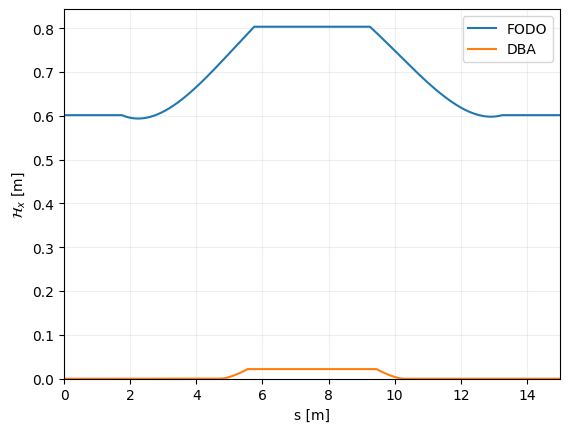

In [42]:
fig, ax = plt.subplots()

ax.plot(tw_fodo.s, tw_fodo.rad_int_curly_hx, label='FODO')
ax.plot(tw_dba.s, tw_dba.rad_int_curly_hx, label='DBA')

ax.set_xlim(0, ring_fodo['l_cell'])
ax.set_ylim(bottom=0)
ax.set_xlabel('s [m]')
ax.set_ylabel(r'$\mathcal{H}_x$ [m]')
ax.legend()
ax.grid(alpha=0.2)

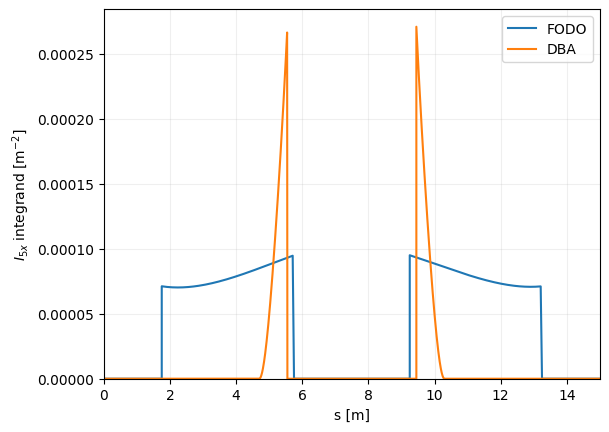

In [43]:
fig, ax = plt.subplots()

ax.plot(tw_fodo.s, tw_fodo.rad_int_i5x_integrand, label='FODO')
ax.plot(tw_dba.s, tw_dba.rad_int_i5x_integrand, label='DBA')

ax.set_xlim(0, ring_fodo['l_cell'])
ax.set_ylim(bottom=0)
ax.set_xlabel('s [m]')
ax.set_ylabel(r'$I_{5x}$ integrand [m$^{-2}$]')
ax.legend()
ax.grid(alpha=0.2)

### Compare the rings

Fill the comparison table in notebook 0 and use these results and plots to answer the questions.